# Lab Assignment 10 — AI in Healthcare (CSET343)
### Beat-level Arrhythmia Classification on MIT-BIH — RNN vs LSTM vs GRU

**Goal:** classify every heartbeat of an ECG into one of the AAMI classes and compare three recurrent networks.

In [1]:
!pip install -q wfdb

import os
import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import tensorflow as tf
from tensorflow.keras import layers, models
from scipy.signal import butter, filtfilt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

---
## Task 1 — Data Acquisition and Exploration

### 1.1 Download MIT-BIH from PhysioNet (wfdb)
48 half-hour recordings, 2 leads, sampled at **360 Hz**.

In [2]:
if not os.path.exists("mitdb/100.dat"):
    wfdb.dl_database("mitdb", dl_dir="mitdb")

records = wfdb.get_record_list("mitdb")
print("Records:", len(records))
print(records)

header = wfdb.rdheader("mitdb/100")
print("Leads:", header.sig_name, "| Sampling rate:", header.fs, "Hz | Length:", header.sig_len / header.fs / 60, "min")

Records: 48
['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']
Leads: ['MLII', 'V5'] | Sampling rate: 360 Hz | Length: 30.092592592592595 min


### 1.2 Plot an ECG Signal with Beat Annotations

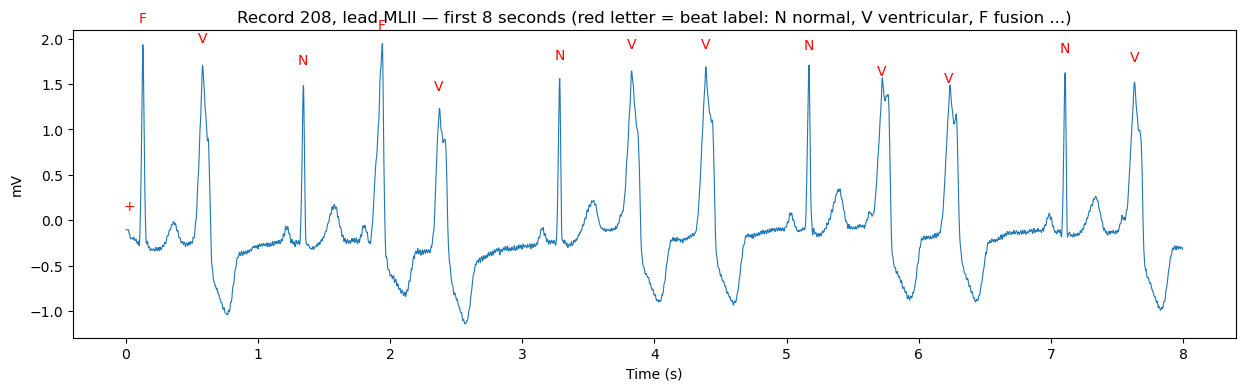

In [3]:
record = wfdb.rdrecord("mitdb/208")
ann = wfdb.rdann("mitdb/208", "atr")
lead = record.sig_name.index("MLII")
signal = record.p_signal[:, lead]

start, end = 0, 360 * 8
t = np.arange(start, end) / 360
plt.figure(figsize=(15, 4))
plt.plot(t, signal[start:end], linewidth=0.8)
for s, sym in zip(ann.sample, ann.symbol):
    if start <= s < end:
        plt.text(s / 360, signal[s] + 0.25, sym, color="red", ha="center")
plt.title("Record 208, lead MLII — first 8 seconds (red letter = beat label: N normal, V ventricular, F fusion ...)")
plt.xlabel("Time (s)"); plt.ylabel("mV")
plt.show()

### 1.3 Map Beat Labels to AAMI Classes and Remove Paced Records / Non-beat Annotations
| AAMI class | Meaning | MIT-BIH symbols |
|---|---|---|
| **N** | Normal and bundle branch block beats | N, L, R, e, j |
| **S** | Supraventricular ectopic beats | A, a, J, S |
| **V** | Ventricular ectopic beats | V, E |
| **F** | Fusion of ventricular and normal | F |
| **Q** | Paced / unclassifiable | /, f, Q |

- Records **102, 104, 107, 217** contain **paced beats** (pacemaker) → removed (AAMI recommendation).
- Annotations like `+` (rhythm change), `~` (noise), `|` (artifact) are **not heartbeats** → removed.

In [4]:
AAMI = {}
for s in "NLRej": AAMI[s] = "N"
for s in "AaJS": AAMI[s] = "S"
for s in "VE": AAMI[s] = "V"
AAMI["F"] = "F"
for s in "/fQ": AAMI[s] = "Q"

PACED = ["102", "104", "107", "217"]
records = [r for r in records if r not in PACED]
print("Records after removing paced:", len(records))

counts = collections.Counter()
non_beat = collections.Counter()
for r in records:
    ann = wfdb.rdann(f"mitdb/{r}", "atr")
    for s in ann.symbol:
        if s in AAMI:
            counts[AAMI[s]] += 1
        else:
            non_beat[s] += 1

print("AAMI class counts:", dict(counts))
print("Non-beat annotations removed:", dict(non_beat))

Records after removing paced: 44


AAMI class counts: {'N': 90125, 'S': 2781, 'V': 7009, 'Q': 15, 'F': 803}
Non-beat annotations removed: {'+': 1173, '~': 573, '|': 131, 'x': 193, '[': 6, '!': 472, ']': 6, '"': 437}


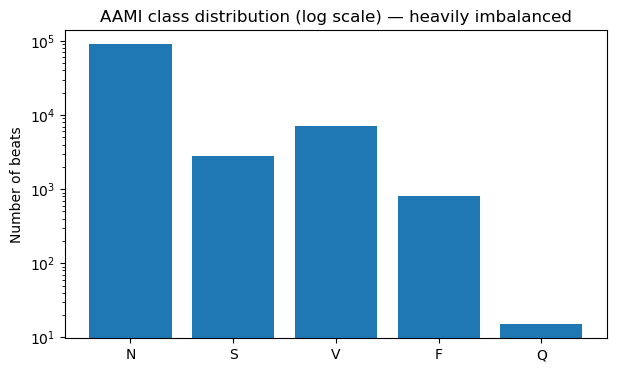

In [5]:
plt.figure(figsize=(7, 4))
order = ["N", "S", "V", "F", "Q"]
plt.bar(order, [counts[c] for c in order])
plt.yscale("log")
plt.title("AAMI class distribution (log scale) — heavily imbalanced")
plt.ylabel("Number of beats")
plt.show()

**Observation:** about **90% of beats are N**. S, V, F are rare, and **Q has only ~15 beats** after removing paced records,
so Q is dropped and we classify **4 classes: N, S, V, F**.

---
## Task 2 — Data Preprocessing

### 2.1 Noise Removal — 0.5–40 Hz Band-pass Filter
- **< 0.5 Hz** removes **baseline wander** (slow drift from breathing / body movement).
- **> 40 Hz** removes **muscle noise and 50/60 Hz power-line interference**.
- `filtfilt` filters forward and backward, so the signal is **not shifted in time**.

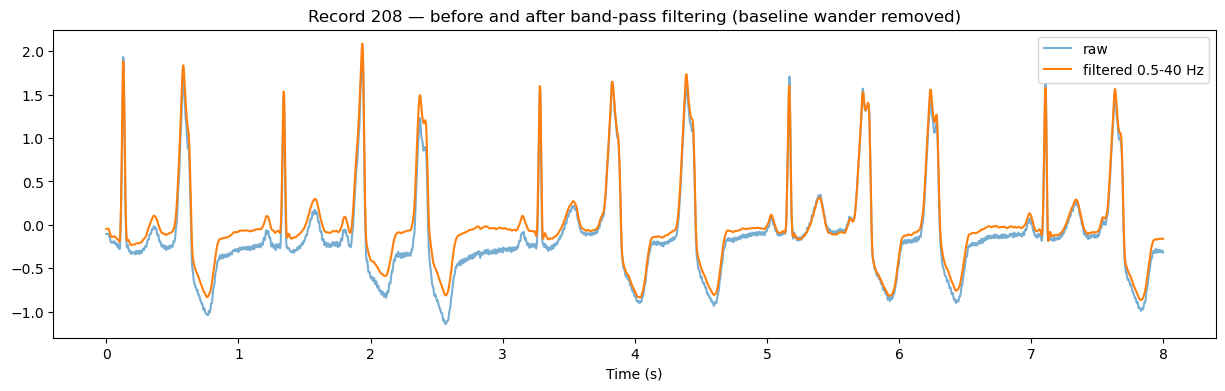

In [6]:
FS = 360
b, a = butter(3, [0.5, 40], btype="bandpass", fs=FS)

raw = signal[:FS * 8]
filtered = filtfilt(b, a, signal)[:FS * 8]

plt.figure(figsize=(15, 4))
plt.plot(np.arange(len(raw)) / FS, raw, label="raw", alpha=0.6)
plt.plot(np.arange(len(raw)) / FS, filtered, label="filtered 0.5-40 Hz")
plt.title("Record 208 — before and after band-pass filtering (baseline wander removed)")
plt.xlabel("Time (s)"); plt.legend()
plt.show()

### 2.2 Segmentation, Feature Extraction and Normalization
For every beat (R-peak from the annotation):
- **Segmentation:** a window of **90 samples before + 90 after** the R-peak = **180 samples = 0.5 s** (raw beat morphology).
- **Normalization:** each window is **z-scored** (mean 0, std 1), so amplitude differences between patients do not matter.
- **RR-interval features:** time to the previous beat (pre-RR) and to the next beat (post-RR), divided by the patient's average RR.
  Premature beats (S, V) come **early**, so RR is a strong clue. They are added as 2 extra channels.

Final input per beat: **(180 time steps × 3 channels)** → [ECG value, pre-RR ratio, post-RR ratio].

In [7]:
HALF = 90
CLASSES = ["N", "S", "V", "F"]

X_all, y_all, rec_all = [], [], []
for r in records:
    record = wfdb.rdrecord(f"mitdb/{r}")
    ann = wfdb.rdann(f"mitdb/{r}", "atr")
    sig = filtfilt(b, a, record.p_signal[:, record.sig_name.index("MLII")])

    beats = [(s, AAMI[sym]) for s, sym in zip(ann.sample, ann.symbol) if sym in AAMI]
    peaks = np.array([s for s, c in beats])
    rr = np.diff(peaks)
    mean_rr = rr.mean()

    for k in range(1, len(beats) - 1):
        s, c = beats[k]
        if c not in CLASSES or s - HALF < 0 or s + HALF > len(sig):
            continue
        win = sig[s - HALF:s + HALF]
        win = (win - win.mean()) / (win.std() + 1e-8)
        pre_rr = rr[k - 1] / mean_rr
        post_rr = rr[k] / mean_rr
        X_all.append(np.stack([win, np.full(2 * HALF, pre_rr), np.full(2 * HALF, post_rr)], axis=1))
        y_all.append(CLASSES.index(c))
        rec_all.append(int(r))

X_all = np.array(X_all, dtype="float32")
y_all = np.array(y_all)
rec_all = np.array(rec_all)
print("Beat tensor:", X_all.shape)
print("Counts:", {CLASSES[i]: int((y_all == i).sum()) for i in range(4)})

Beat tensor: (100630, 180, 3)
Counts: {'N': 90042, 'S': 2779, 'V': 7007, 'F': 802}


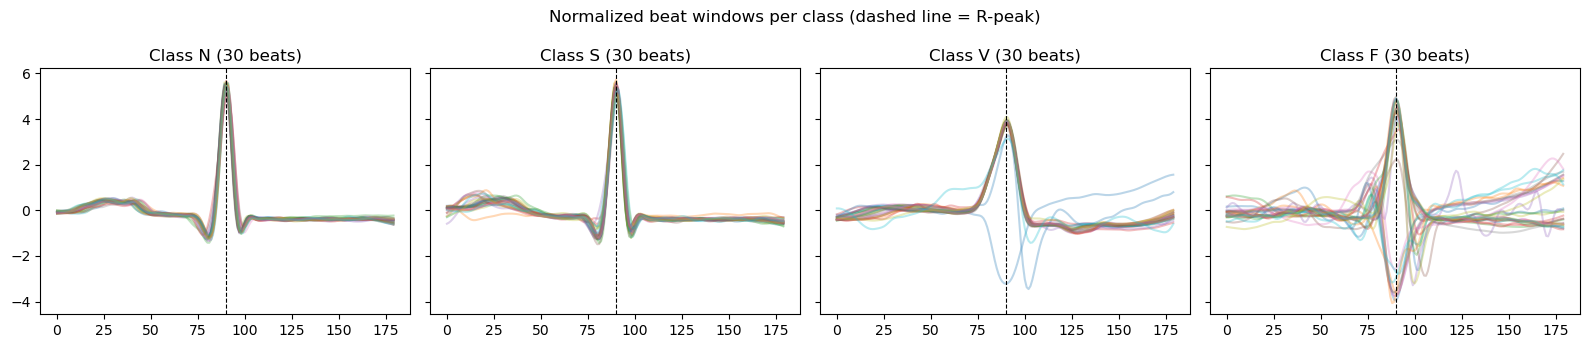

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for i, c in enumerate(CLASSES):
    pick = np.where(y_all == i)[0][:30]
    for p in pick:
        axes[i].plot(X_all[p, :, 0], alpha=0.3)
    axes[i].set_title(f"Class {c} (30 beats)")
    axes[i].axvline(HALF, color="k", linestyle="--", linewidth=0.8)
plt.suptitle("Normalized beat windows per class (dashed line = R-peak)")
plt.tight_layout()
plt.show()

### 2.3 Inter-patient Split (Train / Validation / Test) and Class Imbalance
We use the standard **de Chazal inter-patient split**: the **test patients are never seen in training**, which is how the model would be used on a new patient.
- **DS1 (22 records)** → training + validation (85 / 15, stratified).
- **DS2 (22 records)** → test.

**Class imbalance** is handled in two ways:
1. **Undersampling** the N class in training to 10,000 beats.
2. **Class weights** in the loss, so mistakes on rare classes (S, V, F) cost more.

In [9]:
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]

ds1 = np.isin(rec_all, DS1)
ds2 = np.isin(rec_all, DS2)

X_trval, y_trval = X_all[ds1], y_all[ds1]
X_test, y_test = X_all[ds2], y_all[ds2]

X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.15, stratify=y_trval, random_state=42)

n_idx = np.where(y_train == 0)[0]
other_idx = np.where(y_train != 0)[0]
keep = np.concatenate([np.random.choice(n_idx, 10000, replace=False), other_idx])
np.random.shuffle(keep)
X_train, y_train = X_train[keep], y_train[keep]

weights = compute_class_weight("balanced", classes=np.arange(4), y=y_train)
class_weight = {i: w for i, w in enumerate(weights)}

for name, yy in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{name:5s}:", len(yy), {CLASSES[i]: int((yy == i).sum()) for i in range(4)})
print("Class weights:", {CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

Train: 14373 {'N': 10000, 'S': 801, 'V': 3220, 'F': 352}
Val  : 7646 {'N': 6874, 'S': 142, 'V': 568, 'F': 62}
Test : 49661 {'N': 44218, 'S': 1836, 'V': 3219, 'F': 388}
Class weights: {'N': np.float64(0.36), 'S': np.float64(4.49), 'V': np.float64(1.12), 'F': np.float64(10.21)}


---
## Task 3 — Model Training and Evaluation

### 3.1 Model Design — Comparable RNN, LSTM and GRU
All three models are **identical except for the recurrent layer**:
`Input (180, 3) → Recurrent layer (64 units) → Dense(32, ReLU) → Dropout(0.3) → Dense(4, softmax)`

| Layer | Memory mechanism |
|---|---|
| **SimpleRNN** | One hidden state, no gates → suffers from **vanishing gradients** on long sequences |
| **LSTM** | Cell state + **3 gates** (forget, input, output) → remembers long-range patterns |
| **GRU** | **2 gates** (update, reset) → similar to LSTM but fewer parameters, faster |

### 3.2 Training with Identical Settings and Early Stopping
Same optimizer (Adam, lr = 0.001, gradient clipping), batch size 128, max 40 epochs, same class weights, same random seed,
and **EarlyStopping** (patience 8 on validation loss, best weights restored) for all three.

In [10]:
rnn_types = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}
trained = {}
histories = {}

for name, RecurrentLayer in rnn_types.items():
    tf.keras.utils.set_random_seed(42)
    model = models.Sequential([
        layers.Input((2 * HALF, 3)),
        RecurrentLayer(64),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(4, activation="softmax"),
    ], name=name)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    print(f"\n===== {name}: {model.count_params():,} parameters =====")
    early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    histories[name] = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                epochs=40, batch_size=128, class_weight=class_weight,
                                callbacks=[early_stop], verbose=2)
    trained[name] = model


===== RNN: 6,564 parameters =====
Epoch 1/30


113/113 - 8s - 67ms/step - accuracy: 0.5387 - loss: 1.0459 - val_accuracy: 0.8802 - val_loss: 0.6763


Epoch 2/30


113/113 - 4s - 34ms/step - accuracy: 0.6315 - loss: 0.8524 - val_accuracy: 0.7159 - val_loss: 0.7942


Epoch 3/30


113/113 - 4s - 36ms/step - accuracy: 0.7139 - loss: 0.7134 - val_accuracy: 0.8156 - val_loss: 0.6601


... (83 outputs left out)

Epoch 22/30


113/113 - 5s - 47ms/step - accuracy: 0.9235 - loss: 0.3087 - val_accuracy: 0.8968 - val_loss: 0.3977


Epoch 23/30


113/113 - 6s - 51ms/step - accuracy: 0.9196 - loss: 0.3074 - val_accuracy: 0.8914 - val_loss: 0.4051


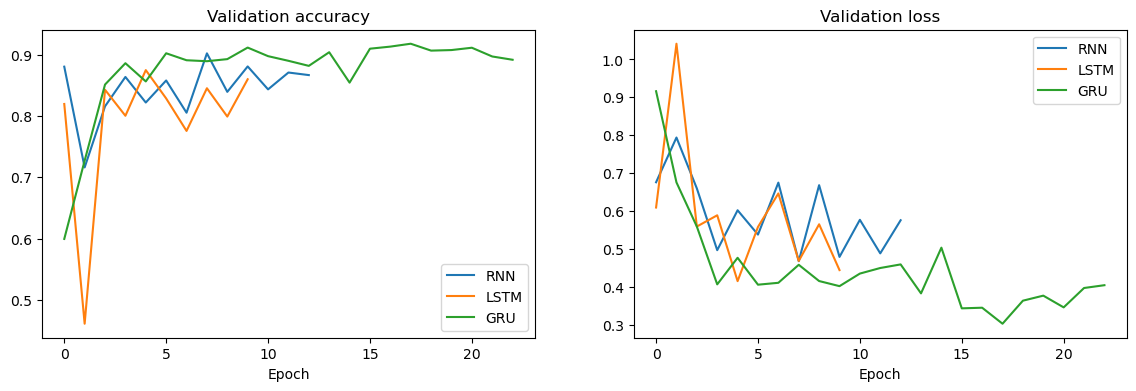

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, h in histories.items():
    axes[0].plot(h.history["val_accuracy"], label=name)
    axes[1].plot(h.history["val_loss"], label=name)
axes[0].set_title("Validation accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Validation loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.show()

### 3.3 Test Set Comparison — Accuracy, Precision, Recall, F1 (macro)

In [12]:
preds = {}
rows = []
for name, model in trained.items():
    preds[name] = model.predict(X_test, verbose=0).argmax(axis=1)
    rows.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Epochs run": len(histories[name].history["loss"]),
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision (macro)": precision_score(y_test, preds[name], average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, preds[name], average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, preds[name], average="macro", zero_division=0),
    })
comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison

,Parameters,Epochs run,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,,,
RNN,6564,13,0.8212,0.4715,0.7671,0.5275
LSTM,19620,10,0.6571,0.3618,0.5695,0.3538
GRU,15460,23,0.7269,0.3909,0.5030,0.3873


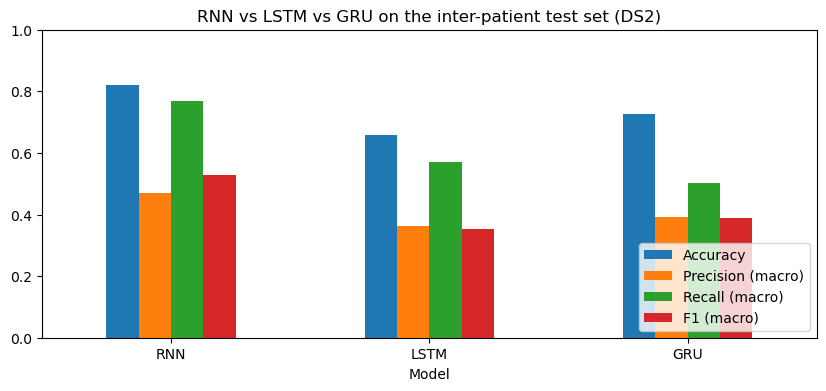

In [13]:
comparison[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]].plot(kind="bar", figsize=(10, 4), rot=0)
plt.ylim(0, 1)
plt.title("RNN vs LSTM vs GRU on the inter-patient test set (DS2)")
plt.legend(loc="lower right")
plt.show()

### 3.4 Per-class Results

In [14]:
for name in trained:
    print(f"===== {name} =====")
    print(classification_report(y_test, preds[name], target_names=CLASSES, digits=3, zero_division=0))

===== RNN =====
              precision    recall  f1-score   support

           N      0.992     0.828     0.903     44218
           S      0.396     0.692     0.504      1836
           V      0.406     0.809     0.541      3219
           F      0.092     0.740     0.163       388

    accuracy                          0.821     49661
   macro avg      0.471     0.767     0.528     49661
weighted avg      0.925     0.821     0.859     49661

===== LSTM =====
              precision    recall  f1-score   support

           N      0.965     0.664     0.787     44218
           S      0.196     0.158     0.175      1836
           V      0.252     0.856     0.389      3219
           F      0.034     0.601     0.065       388

    accuracy                          0.657     49661
   macro avg      0.362     0.570     0.354     49661
weighted avg      0.883     0.657     0.733     49661

===== GRU =====
              precision    recall  f1-score   support

           N      0.991   

### 3.5 Confusion Matrices

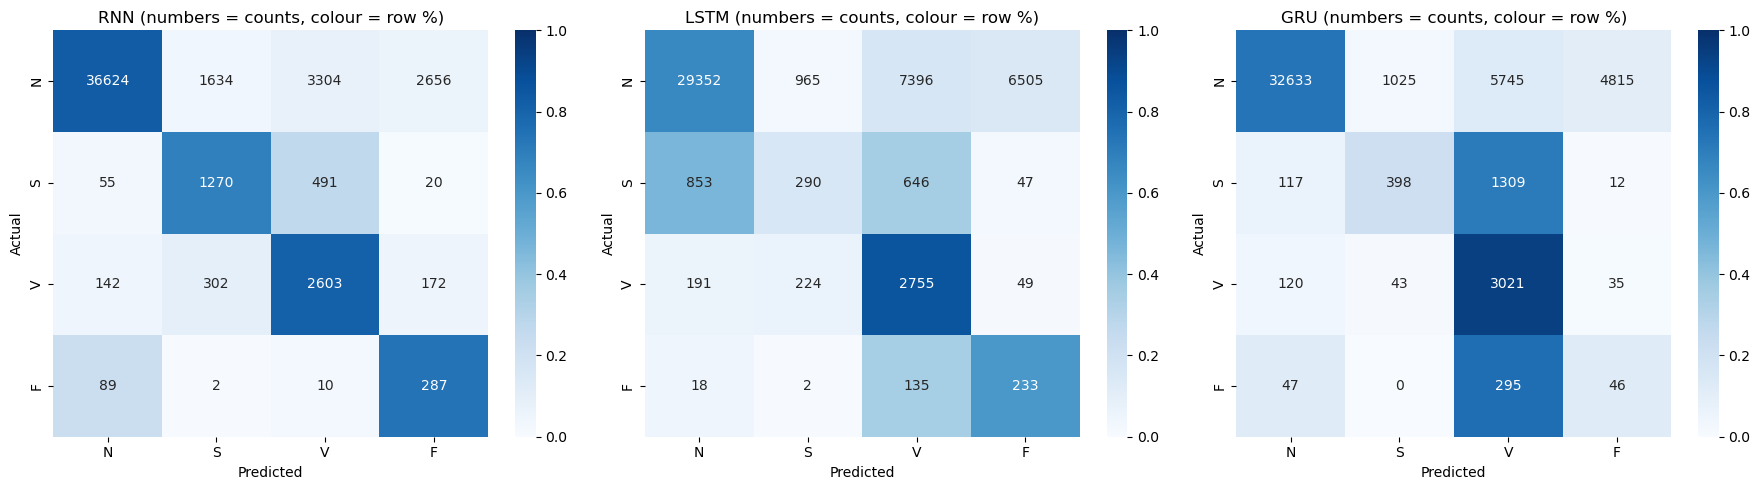

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, trained):
    cm = confusion_matrix(y_test, preds[name])
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_pct, annot=cm, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, vmin=0, vmax=1)
    ax.set_title(f"{name} (numbers = counts, colour = row %)")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()